# Signals, Frequency and Sensor Basics

> **Who is this for:** beginners who know a little Python and NumPy and want to start working with sensor data (phones, watches, machines, cars, robots). No electronics or signal-processing background is needed.
>
> **What you will learn:**
> - what a **sensor** and a **signal** are, and the path from the physical world to numbers in a NumPy array
> - **sampling rate**, the **Nyquist** rule and **aliasing** (with a demo that fools you on purpose)
> - **quantization** and **ADC bits**, the main **noise types** (white noise, bias, drift), **units** and **calibration**
> - the **time domain** vs the **frequency domain**, and the **Fourier transform / FFT** from intuition
> - **frequency resolution**, **windowing** (Hann), and the **spectrogram** (STFT)
> - **filters** (moving average, Butterworth low-pass, high-pass and band-pass), **resampling**, and a short look at **wavelets**
> - how to turn a signal into **features for machine learning** (time-domain, frequency-domain, the MFCC idea)
> - a classic project: tell a **healthy machine from a faulty one** from vibration signals, with FFT features and scikit-learn
>
> **Prerequisites:** [NumPy](../02_Data_Analysis/02_numpy.ipynb), [your first ML model](../03_Machine_Learning/00_start_here_your_first_ml_model.ipynb). Helpful: [time series basics](../04_Forecasting/01_time_series_basics.ipynb), [linear algebra](../14_Mathematics/01_linear_algebra.ipynb).
>
> **Time needed:** about 2-3 hours to read and play (the notebook runs in well under a minute).
>
> **Runs on:** CPU, no API key, no internet. Uses only numpy, scipy, scikit-learn and matplotlib. All data is synthetic (made up by code), so every number below is illustrative.

This is the first notebook of the [Sensor AI track](README.md). Everything later (IMU, radar, LiDAR, sensor fusion) builds on the ideas here.

## 0. Setup

We import the libraries and fix a **random seed**. A seed makes the "random" numbers the same on every run, so your output matches this notebook.

In [1]:
import numpy as np                      # arrays and maths
import matplotlib.pyplot as plt         # plots
from scipy import signal, stats         # signal processing and statistics
from scipy.fft import dct               # discrete cosine transform (used for MFCC)
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

SEED = 42
rng = np.random.default_rng(SEED)       # one random generator for the whole notebook
plt.rcParams["figure.figsize"] = (8, 3) # keep figures small
plt.rcParams["axes.grid"] = True
np.set_printoptions(precision=3, suppress=True)
print("ready")

ready


## 1. What is a sensor? What is a signal?

**What it is.** A **sensor** is a device that measures something in the physical world (temperature, motion, light, sound, distance) and turns it into an electrical value. A **signal** is how that value changes over time (or over space). In code, a signal is usually just a NumPy array of numbers plus the time each number was taken.

**Simple analogy.** A sensor is like a reporter at an event. The reporter (sensor) watches the world and writes a number in a notebook (the signal) every few moments. If the reporter writes too rarely, misses details, or has a bad pen, the story will be wrong. Most of this notebook is about those three problems.

**How it works.** Almost every sensor follows the same chain:

```mermaid
flowchart LR
    W[Physical world<br/>motion, sound, light, heat] --> T[Transducer<br/>turns it into voltage]
    T --> A[Analog electronics<br/>amplifier, anti-alias filter]
    A --> ADC[ADC<br/>samples and rounds<br/>to integers]
    ADC --> D[Digital signal<br/>array of numbers + timestamps]
    D --> P[Pre-processing<br/>calibrate, filter, resample]
    P --> F[Features or raw windows]
    F --> M[ML model<br/>classify, detect, predict]
```

- A **transducer** is the part that converts one kind of energy into another (for example, a tiny moving mass into a voltage).
- An **ADC (analog-to-digital converter)** is the chip that measures the voltage at regular moments and turns it into whole numbers.

A few sensors you will meet in this track (the [README](README.md) has a longer cheat-sheet):

| Sensor | Measures | Typical sampling rate (illustrative) | Notebook |
|---|---|---|---|
| Accelerometer | acceleration (including gravity) along 3 axes | 25-200 Hz in phones and watches | 02 |
| Gyroscope | rotation speed along 3 axes | 25-200 Hz | 02 |
| Microphone | air pressure (sound) | 16,000-48,000 Hz | this one |
| Vibration sensor on a machine | acceleration of the machine casing | 1,000-50,000 Hz | this one |
| Radar | radio echoes (distance, speed, angle) | millions of samples per second inside each chirp | 03 |
| LiDAR | distance by laser time of flight | 10-20 full scans per second | 04 |

## 2. Analog vs digital, and the sampling rate

**What it is.** An **analog** signal exists at every instant (a smooth curve). A **digital** signal only exists at chosen moments, called **samples**. The **sampling rate** `fs` is how many samples we take per second, measured in **hertz (Hz)**. The time between samples is `1/fs`.

**Simple analogy.** A film camera does not record motion. It takes 24 still photos per second, and your brain fills in the gaps. Sampling is the same idea for any signal.

**How it works.** Below, a 5 Hz sine wave (5 full cycles per second) is "the real world". We sample it at three different rates and see what survives.

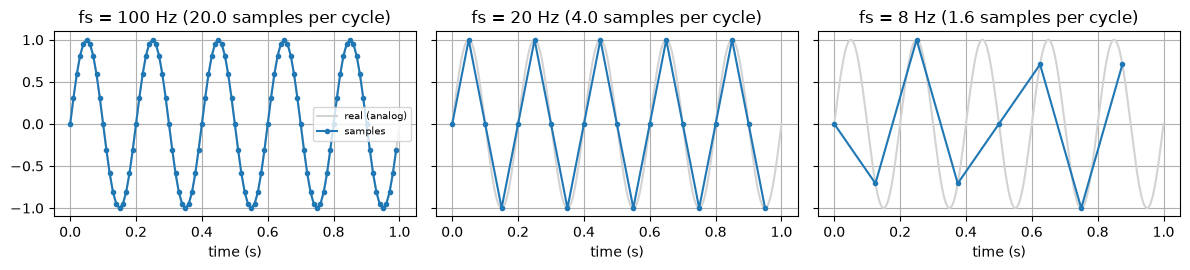

In [2]:
f_true = 5.0                                   # the real signal: 5 cycles per second
t_fine = np.linspace(0, 1, 5000)               # a very fine time grid that "looks analog"
x_fine = np.sin(2 * np.pi * f_true * t_fine)

fig, axes = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
for ax, fs in zip(axes, [100, 20, 8]):         # three sampling rates in Hz
    t_s = np.arange(0, 1, 1 / fs)              # sample times: 0, 1/fs, 2/fs, ...
    ax.plot(t_fine, x_fine, color="lightgray", label="real (analog)")
    ax.plot(t_s, np.sin(2 * np.pi * f_true * t_s), "o-", ms=3, label="samples")
    ax.set_title(f"fs = {fs} Hz ({fs / f_true:.1f} samples per cycle)")
    ax.set_xlabel("time (s)")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

**What just happened?** At 100 Hz the samples follow the wave closely. At 20 Hz we still clearly see 5 cycles. At 8 Hz (fewer than 2 samples per cycle) the dots trace a much slower, wrong wave. That wrong wave is called an **alias**, the topic of the next section.

**When to choose a higher sampling rate:** when the event you care about is fast (an impact, a machine bearing click, a spoken consonant). **When not to:** higher rates cost battery, memory, bandwidth and compute. A step counter does not need 10 kHz.

## 3. Nyquist and aliasing

**What it is.** The **Nyquist rule** says: to capture a frequency `f` correctly you must sample faster than `2 * f`. Half the sampling rate, `fs / 2`, is called the **Nyquist frequency**. Any part of the signal above it does not disappear; it **folds back** and pretends to be a lower frequency. This fake lower frequency is an **alias**, and the effect is **aliasing**.

**Simple analogy.** In films, a fast-spinning car wheel sometimes seems to turn slowly backwards. The camera samples too slowly for the wheel's real speed, so you see a false, slow motion. That is aliasing.

**How it works.** For a sampled sine of frequency `f`, the frequency you *see* is the distance from `f` to the nearest whole multiple of `fs`:

`f_alias = | f - fs * round(f / fs) |`

Let us check this with a 9 Hz sine sampled at 10 Hz. The formula predicts we see 1 Hz.

samples of 9 Hz sine: [ 0.    -0.588 -0.951 -0.951 -0.588  0.   ]
samples of 1 Hz sine: [0.    0.588 0.951 0.951 0.588 0.   ]
predicted alias of 9 Hz at fs=10: 1 Hz


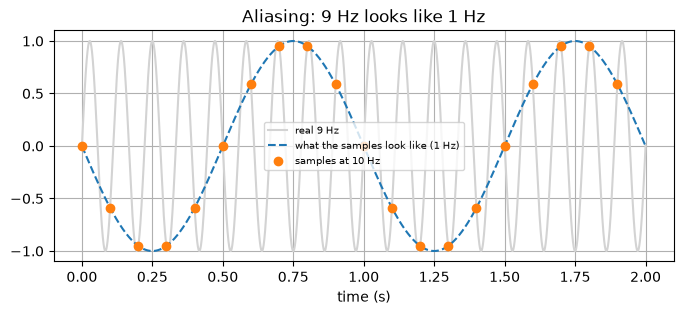

In [3]:
def alias_frequency(f, fs):
    """Frequency we will *see* after sampling a sine of frequency f at rate fs."""
    return abs(f - fs * round(f / fs))

fs = 10.0
t_s = np.arange(0, 2, 1 / fs)                       # 2 seconds of samples at 10 Hz
x9 = np.sin(2 * np.pi * 9 * t_s)                    # a 9 Hz sine, sampled too slowly
x1 = np.sin(2 * np.pi * 1 * t_s)                    # a 1 Hz sine, sampled the same way
print("samples of 9 Hz sine:", x9[:6].round(3))
print("samples of 1 Hz sine:", x1[:6].round(3))
print("predicted alias of 9 Hz at fs=10:", alias_frequency(9, 10), "Hz")

t_fine = np.linspace(0, 2, 4000)
plt.plot(t_fine, np.sin(2 * np.pi * 9 * t_fine), color="lightgray", label="real 9 Hz")
plt.plot(t_fine, -np.sin(2 * np.pi * 1 * t_fine), "--", label="what the samples look like (1 Hz)")
plt.plot(t_s, x9, "o", label="samples at 10 Hz")
plt.legend(fontsize=7); plt.xlabel("time (s)"); plt.title("Aliasing: 9 Hz looks like 1 Hz"); plt.show()

**What just happened?** The samples of the 9 Hz sine are exactly the negative of the 1 Hz samples. After sampling, **no algorithm can tell them apart**. The information is lost forever.

**How real devices avoid it.** They put an analog **anti-aliasing filter** (a low-pass filter, section 11) *before* the ADC. It removes everything above `fs / 2` so nothing can fold back. When you later **downsample** in software, you must low-pass filter first for the same reason (section 12).

A quick table of aliases for `fs = 100 Hz` (Nyquist frequency = 50 Hz):

In [4]:
for f in [10, 40, 50, 60, 90, 110, 160]:
    print(f"real {f:>4} Hz  ->  seen as {alias_frequency(f, 100):>4.0f} Hz")

real   10 Hz  ->  seen as   10 Hz
real   40 Hz  ->  seen as   40 Hz
real   50 Hz  ->  seen as   50 Hz
real   60 Hz  ->  seen as   40 Hz
real   90 Hz  ->  seen as   10 Hz
real  110 Hz  ->  seen as   10 Hz
real  160 Hz  ->  seen as   40 Hz


## 4. Quantization and ADC bits

**What it is.** An ADC can only output whole numbers. An **N-bit** ADC has `2**N` possible levels. Rounding a smooth voltage to the nearest level is called **quantization**, and the rounding error is **quantization noise**.

**Simple analogy.** Measuring your height with a ruler that only has marks every 10 cm. You must round to the nearest mark. A ruler with millimetre marks (more bits) gives a smaller rounding error.

**How it works.** With a full range of `[-1, 1]` and N bits, the step size is `2 / 2**N`. Each extra bit halves the step. For a full-scale sine, a well-known rule of thumb is **SNR = 6.02 * N + 1.76 dB**, where **SNR (signal-to-noise ratio)** compares signal power to noise power, and **dB (decibel)** is a log scale: +10 dB means 10 times more power.

 3 bits:     8 levels, measured SNR =  16.6 dB, rule of thumb =  19.8 dB
 8 bits:   256 levels, measured SNR =  49.7 dB, rule of thumb =  49.9 dB
12 bits:  4096 levels, measured SNR =  73.8 dB, rule of thumb =  74.0 dB


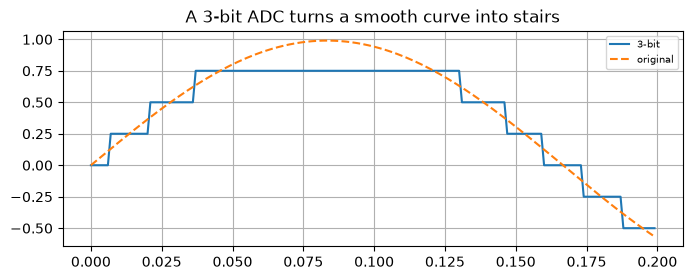

In [5]:
def quantize(x, bits, full_scale=1.0):
    """Round x (assumed in [-full_scale, full_scale]) to the nearest of 2**bits levels."""
    step = 2 * full_scale / (2 ** bits)
    q = np.round(x / step) * step
    return np.clip(q, -full_scale, full_scale - step)

t = np.arange(0, 1, 1 / 1000)
x = 0.99 * np.sin(2 * np.pi * 3 * t)        # nearly full-scale sine

plt.figure(figsize=(8, 2.8))
for bits in [3, 8, 12]:
    xq = quantize(x, bits)
    err = x - xq
    snr_db = 10 * np.log10(np.mean(x**2) / np.mean(err**2))
    print(f"{bits:>2} bits: {2**bits:>5} levels, measured SNR = {snr_db:5.1f} dB,"
          f" rule of thumb = {6.02 * bits + 1.76:5.1f} dB")
    if bits == 3:
        plt.plot(t[:200], xq[:200], label=f"{bits}-bit")
plt.plot(t[:200], x[:200], "--", label="original")
plt.legend(fontsize=7); plt.title("A 3-bit ADC turns a smooth curve into stairs"); plt.show()

**When it matters.** Phone IMUs often use 12-16 bit ADCs, audio uses 16-24 bits. Bits matter most when you need to see **tiny changes on top of a big value** (for example, a 1 mm breathing motion seen by radar in notebook 03, or a small vibration on a large machine). They also matter in ML on tiny devices: **quantizing model weights** to 8 bits (notebook 02) uses exactly the same rounding idea.

## 5. Noise: white noise, bias and drift

**What it is.** **Noise** is any unwanted part of the measurement. Three types matter most for sensors:

| Type | What it looks like | Analogy | Does averaging fix it? |
|---|---|---|---|
| **White noise** | fast random jitter around the true value; equal power at all frequencies | static on a radio | yes, mostly (it shrinks like `1 / sqrt(number of samples)`) |
| **Bias (offset)** | a constant error: the sensor reads +0.05 when the truth is 0 | a bathroom scale that shows 1 kg with nobody on it | no; you must **calibrate** it out |
| **Drift (random walk / bias instability)** | the bias slowly wanders over minutes or with temperature | a clock that runs a bit fast, then a bit slow | no; needs re-calibration or another sensor (sensor fusion, notebook 05) |

Others you may meet: **spikes/outliers** (a loose cable), **1/f (pink) noise** (more power at low frequencies), and **interference** such as 50 or 60 Hz mains hum.

**Demo.** A gyroscope measures rotation speed. To get an angle, you **integrate** (add up) the speed over time. Watch what bias and drift do to the angle of a gyroscope that is actually lying still.

white noise only       angle error after 60 s =  -0.25 deg
white + bias           angle error after 60 s =  11.75 deg
white + bias + drift   angle error after 60 s =   8.26 deg


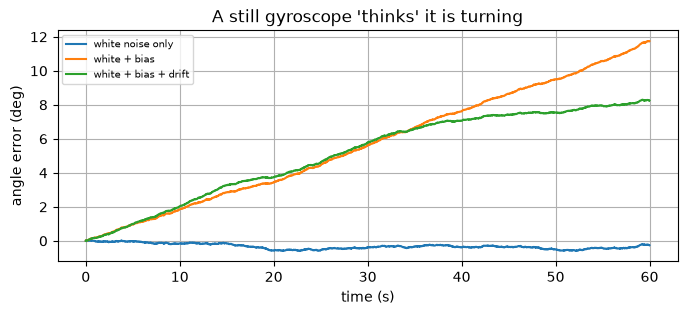

In [6]:
fs = 100                                     # 100 samples per second
t = np.arange(0, 60, 1 / fs)                 # one minute
true_rate = np.zeros_like(t)                 # the gyro is not moving: true speed = 0 deg/s

white = rng.normal(0, 0.5, t.size)           # white noise, std 0.5 deg/s
bias = 0.2                                   # constant bias of 0.2 deg/s
drift = np.cumsum(rng.normal(0, 0.002, t.size))  # slowly wandering bias (random walk)

cases = {"white noise only": true_rate + white,
         "white + bias": true_rate + white + bias,
         "white + bias + drift": true_rate + white + bias + drift}

for name, rate in cases.items():
    angle = np.cumsum(rate) / fs             # integrate: angle = sum(rate * dt)
    plt.plot(t, angle, label=name)
    print(f"{name:<22} angle error after 60 s = {angle[-1]:6.2f} deg")
plt.xlabel("time (s)"); plt.ylabel("angle error (deg)"); plt.legend(fontsize=7)
plt.title("A still gyroscope 'thinks' it is turning"); plt.show()

In [7]:
# Averaging helps white noise but not bias (true value is 0, bias is 0.2):
for n in [10, 100, 1000, 6000]:
    a_white = cases["white noise only"][:n].mean()
    a_bias = cases["white + bias"][:n].mean()
    print(f"average of {n:>4} samples: white only = {a_white:6.3f}   white + bias = {a_bias:6.3f}")

average of   10 samples: white only = -0.168   white + bias =  0.032
average of  100 samples: white only = -0.025   white + bias =  0.175
average of 1000 samples: white only = -0.014   white + bias =  0.186
average of 6000 samples: white only = -0.004   white + bias =  0.196


**What just happened?** White noise alone gives a small error that grows slowly. A tiny bias of 0.2 deg/s becomes a 12 degree error after one minute, because integration adds it up every sample. Averaging many samples removes the white noise but converges to the **bias** (0.2), not the truth (0). This is why a phone cannot track its position for long using only its IMU, and why we fuse sensors in [notebook 05](05_sensor_fusion_kalman_filters_and_tracking.ipynb).

Engineers describe IMU noise with an **Allan variance** plot, which separates white noise, bias instability and random walk by averaging over different time scales. You only need to know the name for now.

## 6. Units and calibration

**What it is.** **Units** say what a number means (m/s², g, deg/s, rad/s, volts, metres). **Calibration** finds the correction that maps raw sensor numbers to true physical values, usually `true = (raw - offset) / scale`.

**Simple analogy.** A new kitchen scale may show 3 g with an empty bowl (offset) and 1,020 g for a 1 kg weight (scale error). Pressing "tare" and checking with a known weight is calibration.

**How it works (accelerometer two-point calibration).** An accelerometer at rest feels only gravity, **1 g ≈ 9.81 m/s²**. If you place it with an axis pointing straight up, that axis should read +1 g; flipped upside down, -1 g. Two known readings give both the offset and the scale.

In [8]:
G = 9.80665                                       # standard gravity in m/s^2
true_offset, true_scale = 0.08, 1.03              # hidden sensor errors (unknown in real life)

def raw_reading(true_g, n=200):
    """Simulate n noisy raw readings (in g) of an accelerometer axis."""
    return true_scale * true_g + true_offset + rng.normal(0, 0.01, n)

up, down = raw_reading(+1).mean(), raw_reading(-1).mean()   # axis up, then flipped
offset = (up + down) / 2                                     # the middle of the two readings
scale = (up - down) / 2                                      # half the distance between them
print(f"raw up = {up:.3f} g, raw down = {down:.3f} g")
print(f"estimated offset = {offset:.3f} (true {true_offset}), scale = {scale:.3f} (true {true_scale})")

test_raw = raw_reading(0.5, n=1).item()                      # a new reading: truly 0.5 g
print(f"new raw reading {test_raw:.3f} g -> calibrated {(test_raw - offset) / scale:.3f} g"
      f" = {(test_raw - offset) / scale * G:.2f} m/s^2")

raw up = 1.109 g, raw down = -0.951 g
estimated offset = 0.079 (true 0.08), scale = 1.030 (true 1.03)
new raw reading 0.607 g -> calibrated 0.513 g = 5.03 m/s^2


**Practical tips.**
- Always write units in variable names or column names (`acc_x_g`, `gyro_z_dps`, `range_m`). Mixing g with m/s² or degrees with radians is one of the most common bugs.
- Each physical device is a little different. A model trained on one phone may fail on another until data is calibrated or normalized.
- **Timestamps** are part of the signal. Two sensors with clocks that differ by 50 ms can make fusion and ML features wrong. Real systems synchronize clocks or align data by timestamp (section 12).

## 7. Time domain vs frequency domain, and the Fourier transform

**What it is.** The **time domain** shows the value at each moment (the plots so far). The **frequency domain** shows *how much of each frequency* the signal contains. The **Fourier transform** converts from time to frequency. The **FFT (fast Fourier transform)** is the fast algorithm computers use to do it.

**Simple analogy.** A smoothie (time signal) is made of fruits (sine waves). The Fourier transform is a recipe-reader: it tastes the smoothie and tells you "2 parts banana, 1 part strawberry, a pinch of mango". Each fruit is one frequency, and the amount is its amplitude.

**How it works.**
1. Any reasonable signal can be written as a sum of sine waves with different frequencies, amplitudes and phases.
2. The FFT compares the signal with a sine at each test frequency (a kind of correlation, or a dot product, see [linear algebra](../14_Mathematics/01_linear_algebra.ipynb)). A big match means "this frequency is present".
3. For a real signal of `N` samples, `np.fft.rfft` returns `N//2 + 1` complex numbers, one per frequency bin from 0 to `fs/2`. Their size `|X|` tells the amount; `2 * |X| / N` gives the sine's amplitude.

Let us **build** a signal from three sines plus noise, and then **recover** them with the FFT.

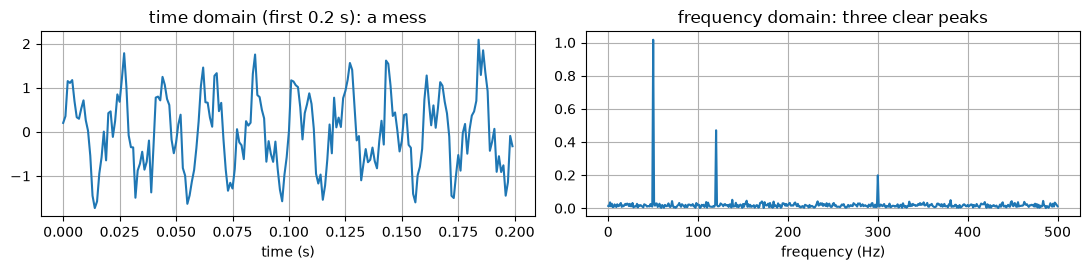

found    50 Hz with amplitude 1.02
found   120 Hz with amplitude 0.47
found   300 Hz with amplitude 0.20


In [9]:
fs = 1000                                     # 1000 samples per second
N = 1000                                      # 1 second of data
t = np.arange(N) / fs
parts = {50: 1.0, 120: 0.5, 300: 0.2}         # frequency (Hz) -> amplitude
x = sum(a * np.sin(2 * np.pi * f * t) for f, a in parts.items())
x = x + rng.normal(0, 0.3, N)                 # add white noise

X = np.fft.rfft(x)                            # complex spectrum
freqs = np.fft.rfftfreq(N, d=1 / fs)          # the frequency of each bin
amp = 2 * np.abs(X) / N                       # convert to sine amplitude

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 2.8))
a1.plot(t[:200], x[:200]); a1.set_title("time domain (first 0.2 s): a mess"); a1.set_xlabel("time (s)")
a2.plot(freqs, amp); a2.set_title("frequency domain: three clear peaks"); a2.set_xlabel("frequency (Hz)")
plt.tight_layout(); plt.show()

top = np.argsort(amp)[-3:][::-1]              # the three biggest peaks
for k in top:
    print(f"found {freqs[k]:5.0f} Hz with amplitude {amp[k]:.2f}")

**What just happened?** The time plot looks like noise, but the spectrum shows three clean peaks at 50, 120 and 300 Hz with amplitudes close to 1.0, 0.5 and 0.2. That is the main reason the frequency domain is so useful for sensors: **many physical things are periodic** (engines, footsteps, heartbeats, breathing, power lines), and periodic things become sharp, easy-to-read peaks.

We can also go back: `np.fft.irfft` (inverse FFT) rebuilds the time signal from the spectrum. That lets us remove a frequency by zeroing its bins and transforming back (a crude filter; section 11 shows better ones).

In [10]:
X_clean = X.copy()
X_clean[np.abs(freqs - 50) < 3] = 0           # delete everything near 50 Hz
x_back = np.fft.irfft(X_clean, n=N)
amp_back = 2 * np.abs(np.fft.rfft(x_back)) / N
print("amplitude at 50 Hz before:", amp[freqs == 50].round(2), " after removing:", amp_back[freqs == 50].round(2))

amplitude at 50 Hz before: [1.02]  after removing: [0.]


## 8. Frequency resolution vs window length

**What it is.** **Frequency resolution** is the spacing between FFT bins: `df = fs / N = 1 / (window duration in seconds)`. To separate two close frequencies, you need a **long enough** window.

**Simple analogy.** To tell whether two singers are slightly out of tune with each other, you must listen for a while. In a 0.1 s clip, you cannot hear the difference.

**How it works.** Two tones at 10 Hz and 10.5 Hz differ by 0.5 Hz. With a 1 s window, `df = 1 Hz`, too coarse. With 4 s, `df = 0.25 Hz`, enough.

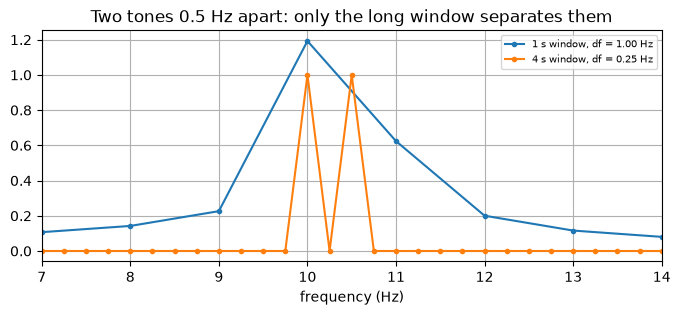

In [11]:
fs = 100
for seconds in [1, 4]:
    t = np.arange(0, seconds, 1 / fs)
    x = np.sin(2 * np.pi * 10 * t) + np.sin(2 * np.pi * 10.5 * t)
    amp = 2 * np.abs(np.fft.rfft(x)) / len(x)
    f = np.fft.rfftfreq(len(x), 1 / fs)
    plt.plot(f, amp, "o-", ms=3, label=f"{seconds} s window, df = {fs / len(x):.2f} Hz")
plt.xlim(7, 14); plt.xlabel("frequency (Hz)"); plt.legend(fontsize=7)
plt.title("Two tones 0.5 Hz apart: only the long window separates them"); plt.show()

**The trade-off.** A long window gives fine frequency detail but blurs **when** things happened. A short window tells you *when* but not exactly *which frequency*. This is the time-frequency trade-off, and it drives the choice of window length in every spectrogram (section 10) and in every ML window (notebook 02).

**Zero padding** (adding zeros before the FFT, `np.fft.rfft(x, n=4*N)`) makes the plot smoother, but it does **not** add real resolution. Only more real data does.

## 9. Spectral leakage and windowing (Hann)

**What it is.** The FFT assumes the window repeats forever. If a sine does not fit a whole number of cycles in the window, the ends do not join, and its energy **leaks** into many nearby bins. This is **spectral leakage**. A **window function** such as the **Hann window** smoothly fades the signal to zero at both ends, which greatly reduces leakage.

**Simple analogy.** Cutting a song in the middle of a note makes a click. Fading in and out avoids the click. The Hann window is a fade-in/fade-out.

**How it works.** Multiply the signal by `np.hanning(N)` (or `signal.windows.hann(N)`) before the FFT. You trade slightly wider peaks for much lower leakage. Below we look on a **log scale (dB)** to see small leaks next to a big peak, which is exactly the situation of a weak target next to a strong one in radar (notebook 03).

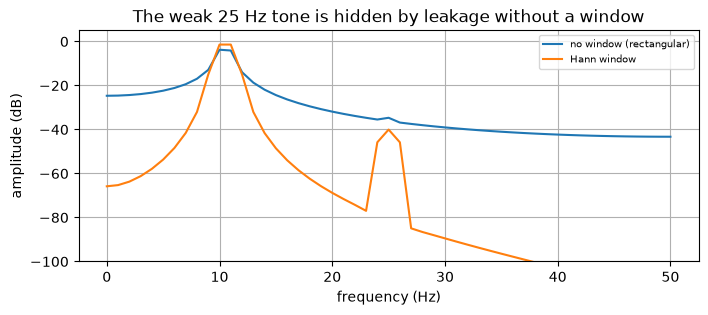

In [12]:
fs, N = 100, 100
t = np.arange(N) / fs
x = np.sin(2 * np.pi * 10.5 * t) + 0.01 * np.sin(2 * np.pi * 25 * t)  # strong tone + very weak tone
f = np.fft.rfftfreq(N, 1 / fs)
for name, w in [("no window (rectangular)", np.ones(N)), ("Hann window", np.hanning(N))]:
    amp = np.abs(np.fft.rfft(x * w)) / w.sum() * 2
    plt.plot(f, 20 * np.log10(amp + 1e-12), label=name)
plt.ylim(-100, 5); plt.xlabel("frequency (Hz)"); plt.ylabel("amplitude (dB)"); plt.legend(fontsize=7)
plt.title("The weak 25 Hz tone is hidden by leakage without a window"); plt.show()

**When to use a window:** almost always before an FFT on a chunk cut out of a longer signal (spectrograms, radar range FFTs, feature extraction). **When not to:** for very short transient events that already start and end at zero.

## 10. The spectrogram (STFT)

**What it is.** A **spectrogram** shows how the frequency content changes over time. It is made by the **STFT (short-time Fourier transform)**: cut the signal into short overlapping windows, apply a Hann window to each, take the FFT of each, and stack the results side by side. The result is a 2-D image: time on the x-axis, frequency on the y-axis, colour for strength.

**Simple analogy.** Sheet music. Notes (frequencies) are written from left (early) to right (late).

**How it works.** Below: a **chirp** (a tone whose frequency rises over time), plus a short 300 Hz beep in the middle. A single FFT would show a smear; the spectrogram shows both clearly. Spectrograms are the input of most audio models and of radar micro-Doppler classifiers (notebook 03), and a CNN can treat them like images.

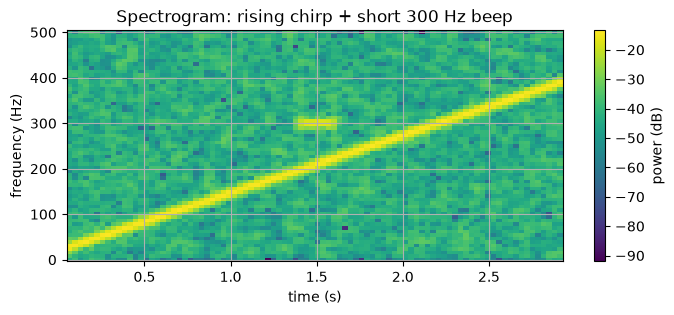

spectrogram shape (frequency bins, time frames): (65, 90)


In [13]:
fs = 1000
t = np.arange(0, 3, 1 / fs)
x = signal.chirp(t, f0=20, t1=3, f1=400)                       # 20 Hz -> 400 Hz over 3 s
beep = (t > 1.4) & (t < 1.6)
x = x + 0.8 * beep * np.sin(2 * np.pi * 300 * t) + rng.normal(0, 0.2, t.size)

f, tt, Sxx = signal.spectrogram(x, fs=fs, window="hann", nperseg=128, noverlap=96)
plt.pcolormesh(tt, f, 10 * np.log10(Sxx + 1e-12), shading="auto")
plt.xlabel("time (s)"); plt.ylabel("frequency (Hz)"); plt.colorbar(label="power (dB)")
plt.title("Spectrogram: rising chirp + short 300 Hz beep"); plt.show()
print("spectrogram shape (frequency bins, time frames):", Sxx.shape)

Try changing `nperseg` (the window length) to 32 or 512 and re-run. Short windows show *when* the beep happens sharply but blur frequency; long windows do the opposite (the trade-off from section 8). `noverlap` is how many samples neighbouring windows share; 50-75% overlap is common.

## 11. Filtering

**What it is.** A **filter** keeps the frequencies you want and removes the rest.

| Filter | Keeps | Typical sensor use |
|---|---|---|
| **Low-pass** | slow parts | remove jitter; get gravity/orientation from an accelerometer; anti-aliasing |
| **High-pass** | fast parts | remove gravity and slow drift; keep body movement |
| **Band-pass** | a range | heart rate from PPG (about 0.7-3 Hz), breathing (about 0.1-0.5 Hz), a machine's bearing band |
| **Band-stop / notch** | everything except a narrow range | remove 50/60 Hz mains hum |

**Simple analogy.** A coffee filter lets liquid through and stops the grounds. A low-pass filter lets slow changes through and stops fast jitter.

**How it works.**
- The **moving average** replaces each sample with the mean of its neighbours. It is the simplest low-pass filter.
- A **Butterworth filter** is a classic design with a very flat response in the band it keeps. Its **order** controls how sharp the cut is (higher order = steeper, but more delay and risk of instability). In SciPy: `signal.butter(order, cutoff, btype, fs=fs, output="sos")`. **SOS (second-order sections)** is the numerically safe format.
- `signal.sosfiltfilt` runs the filter forwards and backwards, so there is **no time delay** (zero phase). It needs the whole recording, so it is for **offline** analysis. For **real-time** use on a device you must use a **causal** filter (`signal.sosfilt`), which only uses past samples and therefore adds some delay.

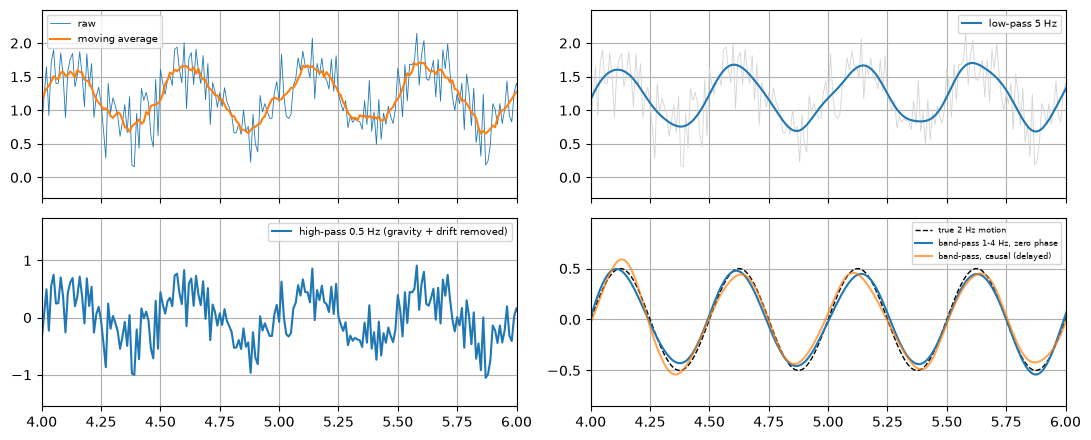

error of band-pass vs true motion (std): 0.091


In [14]:
fs = 100
t = np.arange(0, 10, 1 / fs)
slow = 1.0 + 0.3 * t / 10                        # gravity plus slow drift (near 0 Hz)
body = 0.5 * np.sin(2 * np.pi * 2 * t)           # walking motion at 2 Hz
jitter = 0.3 * rng.normal(size=t.size)           # fast white noise
x = slow + body + jitter

def butter(kind, cutoff, order=4):
    """Return a Butterworth filter in SOS form."""
    return signal.butter(order, cutoff, btype=kind, fs=fs, output="sos")

ma = np.convolve(x, np.ones(9) / 9, mode="same")            # 9-sample moving average
low = signal.sosfiltfilt(butter("lowpass", 5), x)           # keep < 5 Hz
high = signal.sosfiltfilt(butter("highpass", 0.5), x)       # keep > 0.5 Hz
band = signal.sosfiltfilt(butter("bandpass", [1, 4]), x)    # keep 1-4 Hz
causal = signal.sosfilt(butter("bandpass", [1, 4]), x)      # real-time version (has delay)

fig, axes = plt.subplots(2, 2, figsize=(11, 4.5), sharex=True)
axes[0, 0].plot(t, x, lw=0.6, label="raw"); axes[0, 0].plot(t, ma, label="moving average"); axes[0, 0].legend(fontsize=7)
axes[0, 1].plot(t, x, lw=0.6, color="lightgray"); axes[0, 1].plot(t, low, label="low-pass 5 Hz"); axes[0, 1].legend(fontsize=7)
axes[1, 0].plot(t, high, label="high-pass 0.5 Hz (gravity + drift removed)"); axes[1, 0].legend(fontsize=7)
axes[1, 1].plot(t, body, "k--", lw=1, label="true 2 Hz motion")
axes[1, 1].plot(t, band, label="band-pass 1-4 Hz, zero phase")
axes[1, 1].plot(t, causal, alpha=0.7, label="band-pass, causal (delayed)")
axes[1, 1].set_xlim(4, 6); axes[1, 1].legend(fontsize=6)
plt.tight_layout(); plt.show()
print("error of band-pass vs true motion (std):", np.std(band - body).round(3))

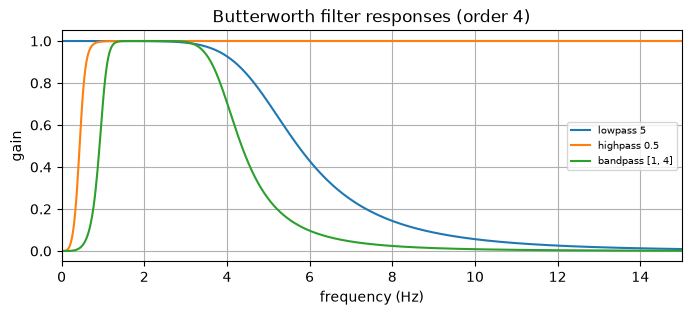

In [15]:
# The frequency response shows what each filter keeps (1.0) and removes (near 0).
for kind, cut in [("lowpass", 5), ("highpass", 0.5), ("bandpass", [1, 4])]:
    w, h = signal.sosfreqz(butter(kind, cut), worN=2000, fs=fs)
    plt.plot(w, np.abs(h), label=f"{kind} {cut}")
plt.xlim(0, 15); plt.xlabel("frequency (Hz)"); plt.ylabel("gain"); plt.legend(fontsize=7)
plt.title("Butterworth filter responses (order 4)"); plt.show()

**When to filter:** to remove noise you understand (mains hum, gravity, drift) or to focus on a known band. **When not to:** do not filter away the information your model needs. For example, the sharp impact spike of a fall (notebook 02) is a high-frequency event, and a strong low-pass filter can flatten it. When in doubt, compare model results with and without the filter.

## 12. Resampling and aligning sensors

**What it is.** **Resampling** changes the sampling rate. **Downsampling** (fewer samples) saves memory and compute; **upsampling** (more samples) is mostly used to **align** sensors with different rates on one time grid.

**How it works.**
- Downsample safely with `signal.decimate` or `signal.resample_poly`. Both apply a low-pass anti-aliasing filter first (section 3). Simply taking every k-th sample (`x[::k]`) can create aliases.
- To align two sensors (for example, an accelerometer at 100 Hz and a heart-rate sensor at 25 Hz), interpolate both onto common timestamps with `np.interp`.

In [16]:
fs_hi = 1000
t = np.arange(0, 1, 1 / fs_hi)
x = np.sin(2 * np.pi * 5 * t) + 0.5 * np.sin(2 * np.pi * 180 * t)   # 5 Hz we want + 180 Hz we do not

naive = x[::10]                               # take every 10th sample -> 100 Hz, no filter
safe = signal.decimate(x, 10)                 # filter, then keep every 10th -> 100 Hz
f100 = np.fft.rfftfreq(naive.size, 1 / 100)
for name, y in [("naive x[::10]", naive), ("signal.decimate", safe)]:
    amp = 2 * np.abs(np.fft.rfft(y)) / y.size
    print(f"{name:<16} strongest frequencies: {f100[np.argsort(amp)[-2:]][::-1]} Hz,"
          f" amplitudes {np.sort(amp)[-2:][::-1].round(2)}")
print("180 Hz at fs=100 aliases to", alias_frequency(180, 100), "Hz")

# Aligning two sensors with different rates onto a 50 Hz grid
t_acc = np.arange(0, 2, 1 / 100); acc = np.sin(2 * np.pi * 1 * t_acc)        # 100 Hz sensor
t_hr = np.arange(0, 2, 1 / 25) + 0.013; hr = 70 + np.cos(2 * np.pi * 0.5 * t_hr)  # 25 Hz, offset clock
t_common = np.arange(0.02, 1.98, 1 / 50)
aligned = np.column_stack([np.interp(t_common, t_acc, acc), np.interp(t_common, t_hr, hr)])
print("aligned table shape (samples, sensors):", aligned.shape)

naive x[::10]    strongest frequencies: [ 5. 20.] Hz, amplitudes [1.  0.5]
signal.decimate  strongest frequencies: [ 5. 44.] Hz, amplitudes [1. 0.]
180 Hz at fs=100 aliases to 20 Hz
aligned table shape (samples, sensors): (98, 2)


**What just happened?** The naive version shows a fake 20 Hz component with amplitude near 0.5: the 180 Hz part folded down. `decimate` removed it first, so only the real 5 Hz survives.

## 13. Wavelets (brief)

**What it is.** The FFT uses endless sine waves, so it is great for steady, repeating signals but poor at saying **when** a short event happened. A **wavelet** is a short "wiggle" that is stretched or squeezed and slid along the signal. The **wavelet transform** tells you which scales (roughly, frequencies) are present **at each moment**: long wavelets for slow changes, short wavelets for sharp spikes.

**Simple analogy.** The FFT is like listening to a whole song and listing its notes. Wavelets are like a highlighter pen: they mark where in the song a drum hit happened.

**How it works (Haar wavelet, the simplest one).** At each level, split the signal into pairs of samples. The **average** of each pair is the smooth part, and the **difference** is the detail. Repeat on the smooth part. Big detail values show where sudden changes are. In practice people use the `PyWavelets` library (not used here, to keep dependencies small).

In [17]:
def haar_dwt(x, levels=4):
    """Simple multi-level Haar wavelet transform. Returns the list of detail arrays."""
    details, approx = [], np.asarray(x, float)
    for _ in range(levels):
        approx = approx[: len(approx) // 2 * 2]                 # make the length even
        a = (approx[0::2] + approx[1::2]) / np.sqrt(2)          # smooth part
        d = (approx[0::2] - approx[1::2]) / np.sqrt(2)          # detail part
        details.append(d); approx = a
    return details

fs = 256
t = np.arange(0, 4, 1 / fs)
x = np.sin(2 * np.pi * 3 * t) + 0.05 * rng.normal(size=t.size)
x[int(2.5 * fs)] += 2.0                                         # a short spike at t = 2.5 s (a "click")
d1 = haar_dwt(x)[0]                                             # finest details (level 1)
spike_index = np.argmax(np.abs(d1))
print(f"level-1 detail is largest at t = {spike_index * 2 / fs:.2f} s (spike was at 2.50 s)")

level-1 detail is largest at t = 2.50 s (spike was at 2.50 s)


**When to use wavelets:** short transients (bearing clicks, ECG QRS complexes, impacts), denoising while keeping sharp edges, and signals whose frequency changes quickly. **When not to:** steady periodic signals, where the FFT is simpler and easier to explain.

## 14. Feature extraction for ML

**What it is.** A **feature** is a single number that summarizes a window of signal (for example, "the average energy" or "the strongest frequency"). Classical ML models (random forests, gradient boosting, logistic regression) need a fixed-length table of features. Deep models (CNNs, RNNs, transformers) can learn features themselves from raw windows, but need more data.

**How it works.** Cut the signal into **windows** (for example, 2.56 s), compute a list of features per window, and use each window as one row of the table.

| Group | Feature | What it captures |
|---|---|---|
| Time domain | mean, std, min, max, range | level and spread |
| | **RMS** (root mean square) | overall energy |
| | **peak** and **crest factor** (peak / RMS) | spikiness; impacts and clicks raise it |
| | **kurtosis** | how "tailed" the values are; about 3 for Gaussian noise, higher with impulses |
| | skewness, zero-crossing rate | asymmetry, rough "how wiggly" |
| Frequency domain | **dominant frequency** and its amplitude | step rate, engine speed, breathing rate |
| | **band energies** (energy in chosen bands) | which frequency ranges are active |
| | **spectral centroid** | the "centre of mass" of the spectrum |
| | **spectral entropy** | peaky (low) vs spread out (high) spectrum |
| Audio-style | **MFCC** | compact description of the spectrum's shape on a human-like scale |

In [18]:
def time_features(x):
    rms = np.sqrt(np.mean(x**2))
    return {"mean": x.mean(), "std": x.std(), "rms": rms,
            "peak": np.max(np.abs(x)), "crest": np.max(np.abs(x)) / (rms + 1e-12),
            "kurtosis": stats.kurtosis(x, fisher=False), "skew": stats.skew(x),
            "zcr": np.mean(np.abs(np.diff(np.sign(x - x.mean()))) > 0)}

def freq_features(x, fs, bands):
    x = x - x.mean()
    spec = np.abs(np.fft.rfft(x * np.hanning(len(x)))) ** 2            # power spectrum
    f = np.fft.rfftfreq(len(x), 1 / fs)
    p = spec / (spec.sum() + 1e-12)                                     # normalize to sum to 1
    feats = {"dom_freq": f[np.argmax(spec)],
             "centroid": np.sum(f * p),
             "entropy": -np.sum(p * np.log2(p + 1e-12)) / np.log2(len(p))}
    for lo, hi in bands:
        feats[f"band_{lo}_{hi}"] = np.log10(spec[(f >= lo) & (f < hi)].sum() + 1e-12)
    return feats

demo = np.sin(2 * np.pi * 2 * np.arange(0, 2.56, 1 / 50)) + 0.1 * rng.normal(size=128)
print({k: round(float(v), 3) for k, v in time_features(demo).items()})
print({k: round(float(v), 3) for k, v in freq_features(demo, 50, [(0, 1), (1, 3), (3, 10)]).items()})

{'mean': -0.006, 'std': 0.7, 'rms': 0.7, 'peak': 1.156, 'crest': 1.651, 'kurtosis': 1.565, 'skew': -0.061, 'zcr': 0.079}
{'dom_freq': 1.953, 'centroid': 2.198, 'entropy': 0.24, 'band_0_1': -0.434, 'band_1_3': 3.171, 'band_3_10': 0.973}


### The MFCC idea (in five small steps)

**MFCCs (mel-frequency cepstral coefficients)** are the classic features for speech and many sound-based sensor tasks (for example, detecting coughs, glass breaking or a failing pump by its sound).

1. Take the power spectrum of a short frame (about 25 ms for audio).
2. Group the frequencies with **mel filters**: triangular bands that are narrow at low frequencies and wide at high frequencies, like human hearing. The **mel scale** is `mel = 2595 * log10(1 + f / 700)`.
3. Take the **log** of each band energy (loudness is perceived on a log scale).
4. Apply a **DCT (discrete cosine transform)**, which squeezes the band energies into a few numbers that describe the spectrum's overall shape.
5. Keep the first 12-20 numbers. Those are the MFCCs.

Audio libraries (such as librosa or torchaudio) do this in one line. Here is a tiny version so the idea is not magic:

In [19]:
def mfcc(frame, fs, n_mels=20, n_coeffs=12):
    spec = np.abs(np.fft.rfft(frame * np.hanning(len(frame)))) ** 2
    f = np.fft.rfftfreq(len(frame), 1 / fs)
    mel = lambda hz: 2595 * np.log10(1 + hz / 700)                        # Hz -> mel
    hz = lambda m: 700 * (10 ** (m / 2595) - 1)                           # mel -> Hz
    edges = hz(np.linspace(mel(0), mel(fs / 2), n_mels + 2))              # band edges, equal in mel
    energies = []
    for lo, mid, hi in zip(edges[:-2], edges[1:-1], edges[2:]):           # triangular filters
        tri = np.clip(np.minimum((f - lo) / (mid - lo), (hi - f) / (hi - mid)), 0, None)
        energies.append(np.sum(tri * spec))
    return dct(np.log(np.array(energies) + 1e-10), norm="ortho")[:n_coeffs]

fs_audio = 16000
tt = np.arange(0, 0.025, 1 / fs_audio)                                     # one 25 ms frame
low_hum = np.sin(2 * np.pi * 200 * tt); high_hiss = rng.normal(size=tt.size)
print("MFCC of a low hum :", mfcc(low_hum, fs_audio)[:6].round(1))
print("MFCC of white hiss:", mfcc(high_hiss, fs_audio)[:6].round(1))

MFCC of a low hum :

 [-61.8  37.7  16.9  11.9   7.3   3.5]
MFCC of white hiss: [31.2 -3.2  0.1  0.1  0.1  0.1]


The two sounds give very different MFCC vectors, so a classifier can separate them easily.

## 15. Project: is this machine healthy or faulty? (vibration analysis)

**The task.** Factories glue small accelerometers onto motors, pumps and fans. **Predictive maintenance** means using these vibration signals to spot a fault *before* the machine breaks. We simulate four classes for a motor spinning at about 30 revolutions per second (30 Hz, called **1x**):

| Class | What is physically wrong | What it does to the signal (simplified textbook patterns) |
|---|---|---|
| healthy | nothing | small 1x tone + noise |
| imbalance | mass not centred on the shaft | strong **1x** tone |
| misalignment | two shafts not in line | strong **2x** (60 Hz) and 3x tones |
| bearing fault | a crack on the bearing race | short repeating **impacts** (at a "fault frequency" around 3.6 x the speed) that ring a high-frequency **resonance** of the machine |

**Important realism detail.** Each simulated machine has its own speed, resonance frequency and noise level. We split train and test **by machine** (`GroupKFold`), so the model is always tested on machines it has never seen. Splitting random windows would leak machine-specific details into the test set and give over-optimistic scores (the same idea as leave-one-subject-out in notebook 02).

In [20]:
FS_VIB = 5000                                    # 5 kHz sampling
DUR = 0.5                                        # 0.5 s per recording
CLASSES = ["healthy", "imbalance", "misalignment", "bearing"]

def vibration_sample(kind, machine):
    """One synthetic vibration recording for a given machine (dict of its properties)."""
    t = np.arange(0, DUR, 1 / FS_VIB)
    f1 = machine["speed"] * rng.uniform(0.98, 1.02)                  # running speed varies a little
    x = 0.2 * np.sin(2 * np.pi * f1 * t + rng.uniform(0, 6.3))       # normal 1x
    if kind == "imbalance":
        x += rng.uniform(0.6, 1.2) * np.sin(2 * np.pi * f1 * t + rng.uniform(0, 6.3))
    if kind == "misalignment":
        x += rng.uniform(0.4, 0.9) * np.sin(2 * np.pi * 2 * f1 * t + rng.uniform(0, 6.3))
        x += rng.uniform(0.1, 0.4) * np.sin(2 * np.pi * 3 * f1 * t + rng.uniform(0, 6.3))
    if kind == "bearing":
        f_fault = 3.6 * f1                                           # impacts per second
        impacts = np.zeros_like(t)
        impacts[(np.arange(0, DUR, 1 / f_fault) * FS_VIB).astype(int)] = rng.uniform(1.0, 2.5)
        ring_t = np.arange(0, 0.01, 1 / FS_VIB)                      # each impact rings for 10 ms
        ring = np.exp(-ring_t * 600) * np.sin(2 * np.pi * machine["resonance"] * ring_t)
        x += np.convolve(impacts, ring)[: t.size]
    return x + rng.normal(0, machine["noise"], t.size)

machines = [{"speed": rng.uniform(25, 35), "resonance": rng.uniform(1200, 1800),
             "noise": rng.uniform(0.15, 0.3)} for _ in range(12)]
X_raw, y, groups = [], [], []
for m_id, m in enumerate(machines):
    for label, kind in enumerate(CLASSES):
        for _ in range(15):                                          # 15 recordings per class per machine
            X_raw.append(vibration_sample(kind, m)); y.append(label); groups.append(m_id)
X_raw, y, groups = np.array(X_raw), np.array(y), np.array(groups)
print("dataset:", X_raw.shape, "(recordings, samples);", np.bincount(y), "per class;", len(machines), "machines")

dataset: (720, 2500) (recordings, samples); [180 180 180 180] per class; 12 machines


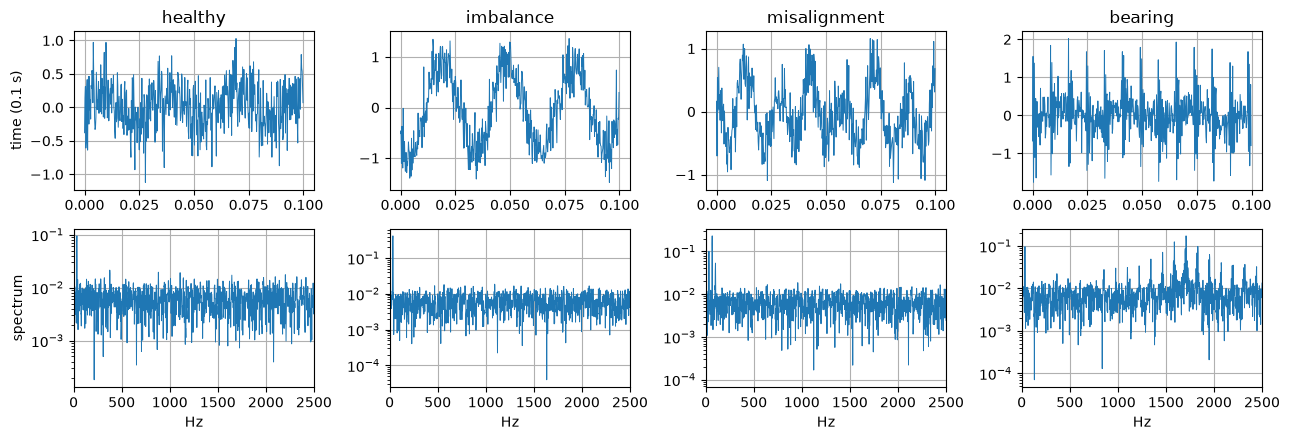

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(13, 4.5))
f = np.fft.rfftfreq(X_raw.shape[1], 1 / FS_VIB)
for c, name in enumerate(CLASSES):
    x = X_raw[np.where(y == c)[0][0]]
    axes[0, c].plot(np.arange(500) / FS_VIB, x[:500], lw=0.7); axes[0, c].set_title(name)
    amp = 2 * np.abs(np.fft.rfft(x * np.hanning(x.size))) / x.size
    axes[1, c].semilogy(f, amp + 1e-5, lw=0.7); axes[1, c].set_xlim(0, 2500)
axes[0, 0].set_ylabel("time (0.1 s)"); axes[1, 0].set_ylabel("spectrum")
for ax in axes[1]: ax.set_xlabel("Hz")
plt.tight_layout(); plt.show()

In the time plots, imbalance and misalignment look like slightly different wobbles, and the bearing fault shows small bursts. In the spectra, each fault has a clear fingerprint: a big 1x peak, extra 2x/3x peaks, or a hump of energy around the resonance (1200-1800 Hz).

Now we build two feature tables: **time-domain only**, and **time + frequency**. The frequency features use bands **relative to the running speed** (1x, 2x, 3x), because in practice the speed is known from a tachometer or from the spectrum itself.

In [22]:
def machine_features(x, use_freq=True):
    feats = time_features(x)
    if use_freq:
        spec = np.abs(np.fft.rfft(x * np.hanning(x.size))) * 2 / np.hanning(x.size).sum()
        f = np.fft.rfftfreq(x.size, 1 / FS_VIB)
        low = (f > 20) & (f < 45)
        f1 = f[low][np.argmax(spec[low])]                         # estimate 1x speed from the spectrum
        for h in [1, 2, 3]:                                       # amplitude at 1x, 2x, 3x
            feats[f"amp_{h}x"] = spec[np.abs(f - h * f1) < 3].max()
        feats.update(freq_features(x, FS_VIB, [(0, 200), (200, 1000), (1000, 2000), (2000, 2500)]))
    return feats

def table(use_freq):
    rows = [machine_features(x, use_freq) for x in X_raw]
    names = list(rows[0].keys())
    return np.array([[r[k] for k in names] for r in rows]), names

cv = GroupKFold(n_splits=4)                                      # test on unseen machines
for use_freq in [False, True]:
    X_feat, names = table(use_freq)
    model = RandomForestClassifier(n_estimators=200, random_state=SEED)
    pred = cross_val_predict(model, X_feat, y, groups=groups, cv=cv)
    print(f"{'time + frequency' if use_freq else 'time-domain only':<18} features={len(names):>2}"
          f"  accuracy on unseen machines = {accuracy_score(y, pred):.3f}")

time-domain only   features= 8  accuracy on unseen machines = 0.954


time + frequency   features=18  accuracy on unseen machines = 0.999


              precision    recall  f1-score   support

     healthy      0.994     1.000     0.997       180
   imbalance      1.000     1.000     1.000       180
misalignment      1.000     1.000     1.000       180
     bearing      1.000     0.994     0.997       180

    accuracy                          0.999       720
   macro avg      0.999     0.999     0.999       720
weighted avg      0.999     0.999     0.999       720



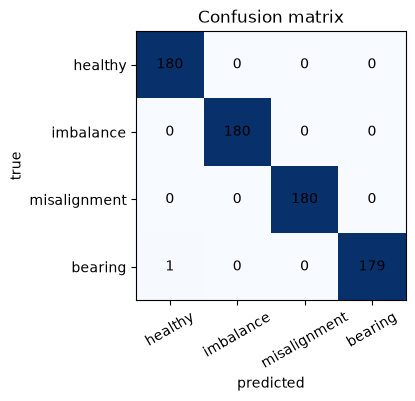

most useful features: ['kurtosis', 'amp_3x', 'amp_1x', 'band_1000_2000', 'amp_2x', 'centroid', 'band_0_200', 'zcr']


In [23]:
print(classification_report(y, pred, target_names=CLASSES, digits=3))
cm = confusion_matrix(y, pred)
plt.figure(figsize=(4, 3.5)); plt.imshow(cm, cmap="Blues")
plt.xticks(range(4), CLASSES, rotation=30); plt.yticks(range(4), CLASSES)
for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Confusion matrix"); plt.grid(False); plt.show()

model = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(X_feat, y)
order = np.argsort(model.feature_importances_)[::-1][:8]
print("most useful features:", [names[i] for i in order])

**What just happened?** Time-domain statistics alone can already catch some faults (RMS rises with imbalance, kurtosis and crest factor rise with bearing impacts), but they mix up classes. Adding frequency features (1x/2x/3x amplitudes, band energies) gives the model the physical fingerprints directly, and the score on **unseen machines** goes up. Exact numbers depend on the synthetic setup; treat them as illustrative. Real factory data is messier (changing loads, several faults at once, different sensor mounting), so expect lower scores and spend most of your time on data quality and honest splits.

### Bonus: envelope analysis for bearing faults

Bearing faults hide their repeat rate inside a high-frequency ringing. The classic trick is **envelope analysis**:

1. Band-pass around the resonance (where the impacts ring).
2. Take the **envelope** (the outline of the bursts) with the **Hilbert transform** (`signal.hilbert`), which gives the "instantaneous amplitude" of a signal.
3. FFT the envelope. A peak appears at the **fault frequency**, which tells you *which* part of the bearing is damaged.

machine speed ~33.7 Hz -> expected fault frequency ~121 Hz
strongest envelope frequency: 122 Hz


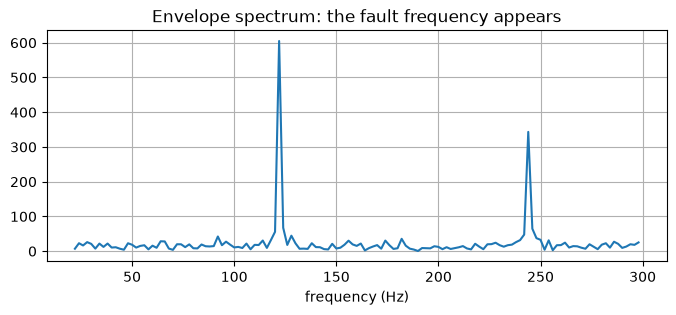

In [24]:
m = machines[0]
x = X_raw[(groups == 0) & (y == 3)][0]                               # a bearing-fault recording from machine 0
band = signal.sosfiltfilt(signal.butter(4, [1000, 2200], btype="band", fs=FS_VIB, output="sos"), x)
env = np.abs(signal.hilbert(band))                                   # the envelope
env_spec = np.abs(np.fft.rfft(env - env.mean()))
f = np.fft.rfftfreq(env.size, 1 / FS_VIB)
keep = (f > 20) & (f < 300)
print(f"machine speed ~{m['speed']:.1f} Hz -> expected fault frequency ~{3.6 * m['speed']:.0f} Hz")
print(f"strongest envelope frequency: {f[keep][np.argmax(env_spec[keep])]:.0f} Hz")
plt.plot(f[keep], env_spec[keep]); plt.xlabel("frequency (Hz)"); plt.title("Envelope spectrum: the fault frequency appears"); plt.show()

## 16. Recap

| Idea | One-line summary | Typical code |
|---|---|---|
| Sampling rate `fs` | samples per second; sample faster than 2x the highest frequency you need | `t = np.arange(N) / fs` |
| Aliasing | frequencies above `fs/2` fold back as fake low frequencies; filter before sampling or downsampling | `signal.decimate` |
| Quantization | an N-bit ADC has `2**N` levels; about 6 dB SNR per bit | `np.round(x / step) * step` |
| Noise types | white (averages out), bias (calibrate), drift (re-calibrate or fuse) | `np.cumsum` shows drift |
| Calibration | `true = (raw - offset) / scale`, from known reference readings | two-point calibration |
| FFT | time signal -> amount of each frequency | `np.fft.rfft`, `np.fft.rfftfreq` |
| Frequency resolution | `df = fs / N = 1 / window_seconds` | longer window = finer detail |
| Windowing | Hann window reduces spectral leakage | `x * np.hanning(N)` |
| Spectrogram (STFT) | FFTs of short overlapping windows, stacked over time | `signal.spectrogram` |
| Filters | low/high/band-pass; zero-phase offline, causal on device | `signal.butter(..., output="sos")`, `sosfiltfilt` / `sosfilt` |
| Wavelets | when *and* which scale; good for short transients | Haar DWT, PyWavelets |
| Features | time stats + spectral features + MFCCs -> a table for ML | `time_features`, `freq_features` |
| Honest evaluation | split by machine / subject / device, not by random window | `GroupKFold` |

## 17. Interview questions

1. **What is the Nyquist frequency, and what happens above it?** It is `fs / 2`. Frequencies above it are not lost silently; they alias (fold back) and look like lower frequencies.
2. **How do you prevent aliasing?** An analog low-pass anti-aliasing filter before the ADC, a high enough sampling rate, and low-pass filtering before any software downsampling (`decimate`, `resample_poly`).
3. **What sets the frequency resolution of an FFT?** The window length in time: `df = 1 / T`. Zero padding interpolates the plot but adds no real resolution.
4. **Why apply a Hann window before an FFT?** To reduce spectral leakage from the abrupt ends of the window, so weak components near strong ones stay visible. The cost is a slightly wider main peak.
5. **Why does a gyroscope's angle drift even when it is still?** Integration adds up the bias and random-walk noise every sample, so the error grows over time. Averaging cannot remove a bias; calibration or fusion with another sensor (accelerometer, magnetometer, camera) is needed.
6. **`filtfilt` vs `lfilter` / `sosfilt`?** `filtfilt` is zero-phase (no delay) but needs future samples, so it is offline only. On a real-time device you use a causal filter and accept some delay.
7. **Which features would you use to detect a bearing fault?** Kurtosis and crest factor (impulsiveness), band energy around the resonance, and the envelope spectrum peak at the bearing fault frequency.
8. **Why split by machine or subject when evaluating?** Windows from the same machine or person are strongly correlated. Random splits leak that identity into the test set and overestimate real-world accuracy.
9. **What is an MFCC, in one sentence?** A compact summary of the shape of a short sound's spectrum: mel-spaced band energies, log, then a DCT, keeping the first few coefficients.

## 18. Further reading

- Steven W. Smith, *The Scientist and Engineer's Guide to Digital Signal Processing* (free online at dspguide.com). Very beginner-friendly.
- Alan V. Oppenheim and Ronald W. Schafer, *Discrete-Time Signal Processing* (the classic university textbook).
- SciPy documentation, `scipy.signal` tutorial: filtering, spectral analysis and the STFT.
- Robert B. Randall and Jérôme Antoni, "Rolling element bearing diagnostics: A tutorial", *Mechanical Systems and Signal Processing*, 2011 (envelope analysis and bearing fault frequencies).
- Case Western Reserve University (CWRU) Bearing Data Center: a widely used real vibration dataset for practice.
- Steven B. Davis and Paul Mermelstein, "Comparison of parametric representations for monosyllabic word recognition in continuously spoken sentences", *IEEE Transactions on Acoustics, Speech, and Signal Processing*, 1980 (the MFCC paper).

**Next:** [02 - IMU activity recognition and fall detection](02_imu_activity_recognition_and_fall_detection.ipynb) uses these tools on accelerometer and gyroscope data.